In [2]:
import numpy as np
import pandas as pd


## Summarise the number of ECG recordings, patients, and features 

In [23]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    f1_score, recall_score, confusion_matrix, roc_curve
)

DATA_DIR = Path("/work/users/m/b/mbonanno/BIOS784_Project/data/processed")
X = np.load(DATA_DIR / "waveforms.npy", mmap_mode="r")
recording_ids = np.load(DATA_DIR / "recording_ids.npy")
labels = pd.read_csv(DATA_DIR / "labels.csv")
predictors = pd.read_csv(DATA_DIR / "predictors.csv")
splits = pd.read_csv(DATA_DIR / "splits.csv")

CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
FS = 100  # Hz

In [26]:
### some standardization for graphs (to make my life easier)
from matplotlib.colors import LinearSegmentedColormap
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
GROUP_COLOR = {"NORM": BLUE, "MI": ORANGE}      # NORM is always blue, MI always orange
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_orange", [BLUE, "#e9e8e4", ORANGE])

In [12]:
for t in (labels, predictors, splits):
    assert np.array_equal(t.ecg_id.to_numpy(), recording_ids), "row order mismatch"

df = (labels[["ecg_id", *CLASSES, "has_diagnostic_label"]]
      .merge(predictors[["ecg_id", "patient_id", "age", "sex"]], on="ecg_id", validate="one_to_one")
      .merge(splits[["ecg_id", "partition"]], on="ecg_id", validate="one_to_one"))
assert np.array_equal(df.ecg_id.to_numpy(), recording_ids)
df["row"] = np.arange(len(df))                 
df["age_clean"] = df.age.where(df.age <= 100)  
PARTS = ["train", "validation", "test"]
n_per_patient = df.groupby("patient_id").size()

In [60]:
overview = pd.Series({
    "ECG recordings": len(df),
    "Unique patients": df.patient_id.nunique(),
    "Patients with >1 recording": int((n_per_patient > 1).sum()),
    "Waveform array shape": str(X.shape),
    "Raw values per recording (1000 x 12)": 1000 * 12,
    "Recordings with a diagnostic label": int(df.has_diagnostic_label.sum()),
    "Recordings with NO diagnostic label": int((df.has_diagnostic_label == 0).sum()),
}, name="value")
display(overview.to_frame())

,value
ECG recordings,21799
Unique patients,18869
Patients with >1 recording,2111
Waveform array shape,"(21799, 1000, 12)"
Raw values per recording (1000 x 12),12000
Recordings with a diagnostic label,21388
Recordings with NO diagnostic label,411


In [61]:
part_tbl = (df.groupby("partition")
              .agg(recordings=("ecg_id", "size"), patients=("patient_id", "nunique"),
                   diagnostic_eligible=("has_diagnostic_label", "sum"))
              .reindex(PARTS))
display(part_tbl)

# Patient separation across partitions must be zero
sets = {p: set(df.loc[df.partition == p, "patient_id"]) for p in PARTS}
print("Patient overlap  train/val:", len(sets["train"] & sets["validation"]),
      "| train/test:", len(sets["train"] & sets["test"]),
      "| val/test:", len(sets["validation"] & sets["test"]))

,recordings,patients,diagnostic_eligible
partition,,,
train,17418,15023,17084
validation,2183,1942,2146
test,2198,1904,2158


Patient overlap  train/val: 0 | train/test: 0 | val/test: 0


In [51]:
# Which summary features exist (statistic-major order, identical to the RF/LR notebooks)
STATS = ["Mean", "Std", "Min", "Max", "RMS"]
FEATURE_NAMES = [f"{s}_{l}" for s in STATS for l in LEADS]
print(len(FEATURE_NAMES), "features, e.g.", FEATURE_NAMES[:3], "...", FEATURE_NAMES[-3:])

# Demographic summary 
demo = df.groupby("partition").agg(
    age_mean=("age_clean", "mean"), age_sd=("age_clean", "std"),
    n_recordings_age_over_89=("age", lambda a: int((a > 100).sum())),   # recordings (not patients) with de-identified age
    female_pct=("sex", lambda s: 100 * s.mean())).reindex(PARTS).round(2)
display(demo)

60 features, e.g. ['Mean_I', 'Mean_II', 'Mean_III'] ... ['RMS_V4', 'RMS_V5', 'RMS_V6']


,age_mean,age_sd,n_recordings_age_over_89,female_pct
partition,,,,
train,59.35,16.63,217,47.82
validation,59.88,17.14,42,48.10
test,60.68,17.32,34,48.50


## Calculate the number and proportion of normal versus MI-related ECGs 

Labels are multilabel, so NORM and MI can overlap. The binary cohort follows logic of the logistic regression notebook: *NORM but not MI*, or *MI but not NORM* (recordings with no diagnostic label are excluded)

In [62]:
is_norm = df.NORM.eq(1) & df.MI.eq(0)
is_mi = df.MI.eq(1) & df.NORM.eq(0)
print("Recordings labelled BOTH NORM and MI:", int((df.NORM.eq(1) & df.MI.eq(1)).sum()))

df["group"] = np.select([is_norm, is_mi], ["NORM", "MI"], default="")
bdf = df[df.group != ""].copy()  # the NORM-vs-MI cohort

counts = (bdf.groupby(["partition", "group"]).size().unstack().reindex(PARTS)[["NORM", "MI"]])
counts.loc["ALL"] = counts.sum()
counts["total"] = counts.sum(axis=1)
counts["NORM_%"] = (100 * counts.NORM / counts.total).round(1)
counts["MI_%"] = (100 * counts.MI / counts.total).round(1)
display(counts)

Recordings labelled BOTH NORM and MI: 1


group,NORM,MI,total,NORM_%,MI_%
partition,,,,,
train,7595,4378,11973,63.4,36.6
validation,955,540,1495,63.9,36.1
test,963,550,1513,63.6,36.4
ALL,9513,5468,14981,63.5,36.5


,count,% of MI
MI recordings,5468,100.0
MI only (no other label),2532,46.3
MI + >=1 other label,2936,53.7
MI + STTC,1339,24.5
MI + CD,1793,32.8
MI + HYP,817,14.9


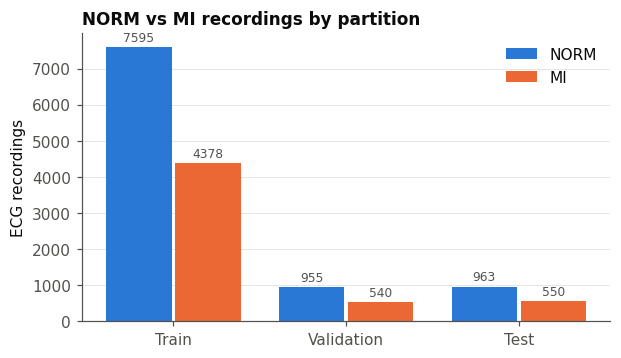

In [20]:

# do we see other classes overlapping with MI?
other = ["STTC", "CD", "HYP"]
mi = bdf[bdf.group == "MI"]
mi_other = pd.DataFrame({"MI recordings": [len(mi)],
    "MI only (no other label)": [int((mi[other].sum(axis=1) == 0).sum())],
    "MI + >=1 other label": [int((mi[other].sum(axis=1) > 0).sum())],
    **{f"MI + {c}": [int(mi[c].sum())] for c in other}}).T.rename(columns={0: "count"})
mi_other["% of MI"] = (100 * mi_other["count"] / len(mi)).round(1)
display(mi_other)

fig, ax = plt.subplots(figsize=(6.2, 3.4))
w = 0.38
xs = np.arange(len(PARTS))
for k, (g, off) in enumerate([("NORM", -w / 2 - 0.01), ("MI", w / 2 + 0.01)]):
    vals = counts.loc[PARTS, g].to_numpy()
    bars = ax.bar(xs + off, vals, width=w, color=GROUP_COLOR[g], label=g)
    ax.bar_label(bars, fmt="%d", padding=2, fontsize=8, color=MUTED)
ax.set_xticks(xs, [p.capitalize() for p in PARTS])
ax.set_ylabel("ECG recordings")
ax.set_title("NORM vs MI recordings by partition")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
#save_fig(fig, "02_norm_vs_mi_counts.png")
plt.show()

## Explore the distributions of selected ECG features - are there differences in ECG features between NORM and MI?

Features are computed from the waveform in batchs). To avoid
looking at the held-out data while choosing what to plot, **effect sizes and the "selected" features come from the
training partition only.** Effect size = Cohen's d (MI minus NORM, in pooled SD units) and the univariate AUROC
(0.5 = no separation). Because the groups differ in age and sex, those are compared at the end of this section.

In [21]:
def extract_features(rows, batch=256):
    """60 features: [Mean x12 | Std x12 | Min x12 | Max x12 | RMS x12].
    Initially pioneered by Shreya B"""
    
    out = np.empty((len(rows), 60), dtype=np.float32)
    for s in range(0, len(rows), batch):
        r = rows[s:s + batch]
        b = np.asarray(X[r], dtype=np.float32)
        out[s:s + len(r)] = np.concatenate(
            [b.mean(1), b.std(1), b.min(1), b.max(1), np.sqrt((b ** 2).mean(1))], axis=1)
    return out

rows = bdf.row.to_numpy()
F = extract_features(rows)
print("computed features", F.shape)
assert np.isfinite(F).all()
feat = pd.DataFrame(F, columns=FEATURE_NAMES, index=bdf.index)

computed features (14981, 60)


In [63]:
def effect_table(frame, groups):
    a = frame[groups == "MI"]
    b = frame[groups == "NORM"]
    rows_ = []
    for c in frame.columns:
        x, y = a[c].to_numpy(), b[c].to_numpy()
        sp = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
        d = (x.mean() - y.mean()) / sp if sp > 0 else 0.0
        u = stats.mannwhitneyu(x, y, alternative="two-sided").statistic
        auc = u / (len(x) * len(y))   # P(MI value > NORM value)
        rows_.append((c, np.median(y), np.median(x), d, auc))
    t = pd.DataFrame(rows_, columns=["feature", "NORM_median", "MI_median", "cohens_d", "AUROC"])
    t["abs_d"] = t.cohens_d.abs()
    return t.sort_values("abs_d", ascending=False).reset_index(drop=True)

tr = bdf.partition == "train"
effects = effect_table(feat[tr], bdf.loc[tr, "group"])
display(effects.head(15).round(3))


,feature,NORM_median,MI_median,cohens_d,AUROC,abs_d
0,Min_III,-0.329,-0.632,-0.901,0.257,0.901
1,Min_aVF,-0.237,-0.374,-0.758,0.312,0.758
2,Std_aVL,0.083,0.117,0.738,0.698,0.738
3,Max_aVL,0.445,0.691,0.707,0.693,0.707
4,Max_II,0.805,0.531,-0.690,0.283,0.690
5,Min_aVR,-0.762,-0.595,0.603,0.678,0.603
6,Std_III,0.092,0.123,0.598,0.663,0.598
7,RMS_aVL,0.083,0.117,0.521,0.698,0.521
8,Min_V4,-0.638,-0.835,-0.500,0.374,0.500
9,Min_V3,-0.962,-1.194,-0.489,0.375,0.489


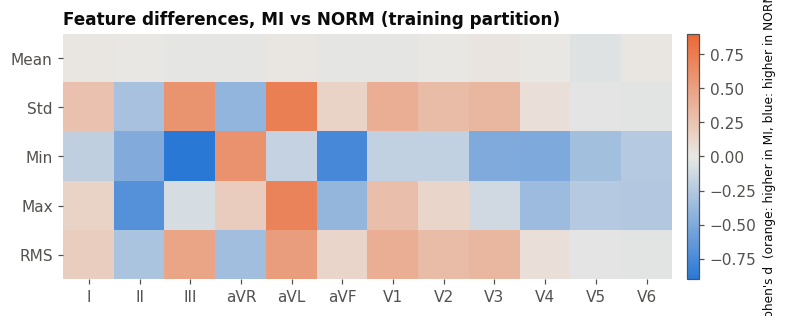

In [27]:

# Heatmap of signed effect sizes: statistic (rows) x lead (columns)
d_mat = (effects.set_index("feature").cohens_d
         .reindex(FEATURE_NAMES).to_numpy().reshape(len(STATS), len(LEADS)))
lim = np.abs(d_mat).max()
fig, ax = plt.subplots(figsize=(8.6, 2.9))
im = ax.imshow(d_mat, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(LEADS)), LEADS)
ax.set_yticks(range(len(STATS)), STATS)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, pad=0.02)
cb.set_label("Cohen's d  (orange: higher in MI, blue: higher in NORM)", fontsize=8)
ax.set_title("Feature differences, MI vs NORM (training partition)")
#save_fig(fig, "03_effect_size_heatmap.png")
plt.show()

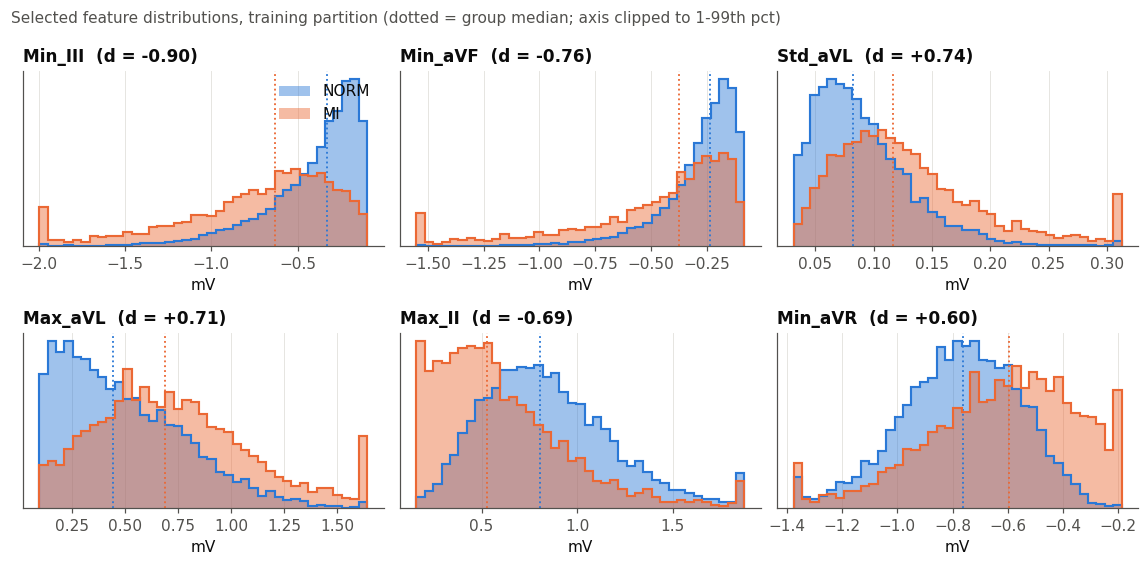

In [64]:
# Distributions of selected features. Default: the 6 largest effects in training.

selected =  effects.feature.head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.2))
for ax, name in zip(axes.flat, selected):
    v = feat.loc[tr, name]
    lo, hi = np.percentile(v, [1, 99])                  # clip display to 1st-99th percentile
    bins = np.linspace(lo, hi, 40)
    for g in ["NORM", "MI"]:
        vals = v[bdf.loc[tr, "group"] == g].clip(lo, hi)
        ax.hist(vals, bins=bins, density=True, histtype="stepfilled", alpha=0.45,
                color=GROUP_COLOR[g], linewidth=0, label=g)
        ax.hist(vals, bins=bins, density=True, histtype="step", color=GROUP_COLOR[g], linewidth=1.4)
        ax.axvline(vals.median(), color=GROUP_COLOR[g], linestyle=":", linewidth=1.2)
    d = effects.set_index("feature").loc[name, "cohens_d"]
    ax.set_title(f"{name}  (d = {d:+.2f})")
    ax.set_xlabel("mV")
    ax.set_yticks([])
axes.flat[0].legend(loc="upper right")
fig.suptitle("Selected feature distributions, training partition (dotted = group median; axis clipped to 1-99th pct)",
             x=0.01, ha="left", fontsize=10, color=MUTED)
fig.tight_layout()
plt.show()



In [29]:
summary = (feat.loc[tr, selected].groupby(bdf.loc[tr, "group"])
           .describe(percentiles=[.25, .5, .75]).T.unstack(0).round(3))
display(summary)

group        MI                                                        NORM  \
        Min_III   Min_aVF   Std_aVL   Max_aVL    Max_II   Min_aVR   Min_III   
count  4378.000  4378.000  4378.000  4378.000  4378.000  4378.000  7595.000   
mean     -0.749    -0.497     0.130     0.736     0.606    -0.626    -0.413   
std       0.481     0.383     0.068     0.379     0.357     0.279     0.294   
min      -3.439    -3.197     0.020     0.062    -0.299    -2.708    -3.591   
25%      -0.972    -0.633     0.084     0.470     0.353    -0.791    -0.538   
50%      -0.632    -0.374     0.117     0.691     0.531    -0.595    -0.329   
75%      -0.404    -0.230     0.158     0.944     0.775    -0.423    -0.210   
max      -0.072    -0.058     0.686     2.843     3.383     0.185     5.453   

group                                                    
        Min_aVF   Std_aVL   Max_aVL    Max_II   Min_aVR  
count  7595.000  7595.000  7595.000  7595.000  7595.000  
mean     -0.287     0.091     0.498     0.850    -0.773  
std       0.189     0.043     0.307     0.350     0.221  
min      -2.334     0.019    -5.341    -0.012    -2.461  
25%      -0.352     0.060     0.260     0.601    -0.912  
50%      -0.237     0.083     0.445     0.805    -0.762  
75%      -0.165     0.112     0.687     1.049    -0.616  
max       2.639     0.607     3.614     3.426     2.055

,n,age_median,age_mean,age_sd,n_recordings_age_over_89,female_pct
group,,,,,,
NORM,9513,54.0,52.05,17.22,31,53.89
MI,5468,67.0,66.26,12.53,121,37.69


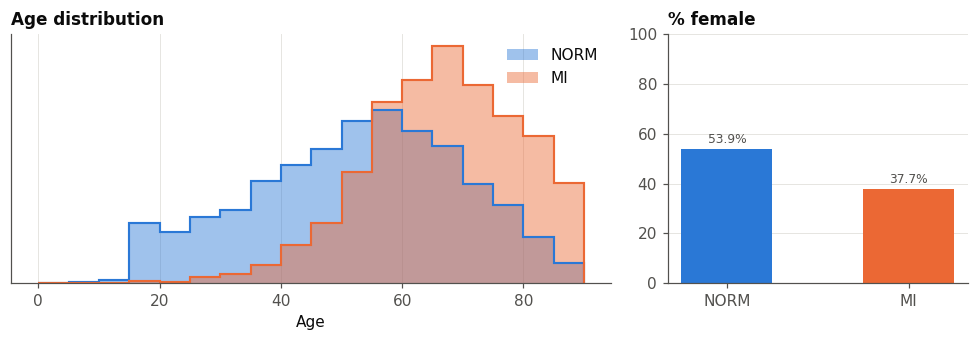

In [65]:
# Confounding check: do NORM and MI differ in age and sex?
dem = bdf.groupby("group").agg(n=("ecg_id", "size"), age_median=("age_clean", "median"),
                               age_mean=("age_clean", "mean"), age_sd=("age_clean", "std"),
                               n_recordings_age_over_89=("age", lambda a: int((a > 100).sum())),
                               female_pct=("sex", lambda s: 100 * s.mean())).round(2).loc[["NORM", "MI"]]
display(dem)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [2, 1]})
bins = np.arange(0, 95, 5)
for g in ["NORM", "MI"]:
    v = bdf.loc[bdf.group == g, "age_clean"].dropna()
    axes[0].hist(v, bins=bins, density=True, histtype="stepfilled", alpha=0.45, color=GROUP_COLOR[g], linewidth=0, label=g)
    axes[0].hist(v, bins=bins, density=True, histtype="step", color=GROUP_COLOR[g], linewidth=1.4)
axes[0].set(title="Age distribution", xlabel="Age")
axes[0].set_yticks([]); axes[0].legend()
fem = dem.female_pct
bars = axes[1].bar(["NORM", "MI"], fem.loc[["NORM", "MI"]], color=[BLUE, ORANGE], width=0.5)
axes[1].bar_label(bars, fmt="%.1f%%", padding=2, fontsize=8, color=MUTED)
axes[1].set(title="% female", ylim=(0, 100)); axes[1].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## Visualise representative normal and MI-related ECG recordings 
*Two views, because they answer different questions.**

*4a. One recording per group (full signal).* "Representative" here has two requirements:
(1) a **typical amplitude profile**: the recording whose standardised 60-feature vector is closest to its group's median
profile, and (2) a **typical patient**: it must be a training recording within `AGE_BAND` years of a target age and of a
target sex. With `MATCH_ACROSS_GROUPS = True` the NORM and MI examples share the same target age and sex, so differences
between them are less likely to be age or sex effects. Set it to `False` to use each group's own median age and most common sex.

*4b. Average beat per group (R-peak aligned).* A raw 10 s trace starts at an arbitrary moment in the heartbeat, so two
recordings never line up in time. To compare shapes we detect each QRS (R peak), cut a window around it, and average.ht.

In [53]:
AGE_BAND = 5                  # +/- years around the target age
MATCH_ACROSS_GROUPS = True    # True: same target age/sex for both groups

trd = bdf[tr]
z_all = (feat - feat[tr].mean()) / feat[tr].std(ddof=0)       # standardise with training statistics

def target_demographics(group):
    src = trd if MATCH_ACROSS_GROUPS else trd[trd.group == group]
    return src.age_clean.median(), int(src.sex.mode().iloc[0])

def representative(group, band=AGE_BAND):
    in_group = (bdf.group == group) & tr
    center = z_all[in_group].median()                          # typical profile of the WHOLE group
    age0, sex0 = target_demographics(group)
    while True:
        cand = in_group & bdf.sex.eq(sex0) & bdf.age_clean.between(age0 - band, age0 + band)
        if cand.sum() >= 20 or band >= 30:                     # widen the band if too few candidates
            break
        band += 2.5
    dist = ((z_all[cand] - center) ** 2).sum(axis=1)
    rec = bdf.loc[dist.idxmin()].copy()
    rec["n_candidates"], rec["age_target"], rec["band_used"] = int(cand.sum()), age0, band
    return rec

LAYOUT = [["I", "aVR", "V1", "V4"], ["II", "aVL", "V2", "V5"], ["III", "aVF", "V3", "V6"]]
SECONDS = 5

,ecg_id,age,sex,target_age,age_band_used,candidates,group_median_age
NORM,20805,64.0,male,59.0,5,917,54.0
MI,10998,61.0,male,59.0,5,1001,66.0


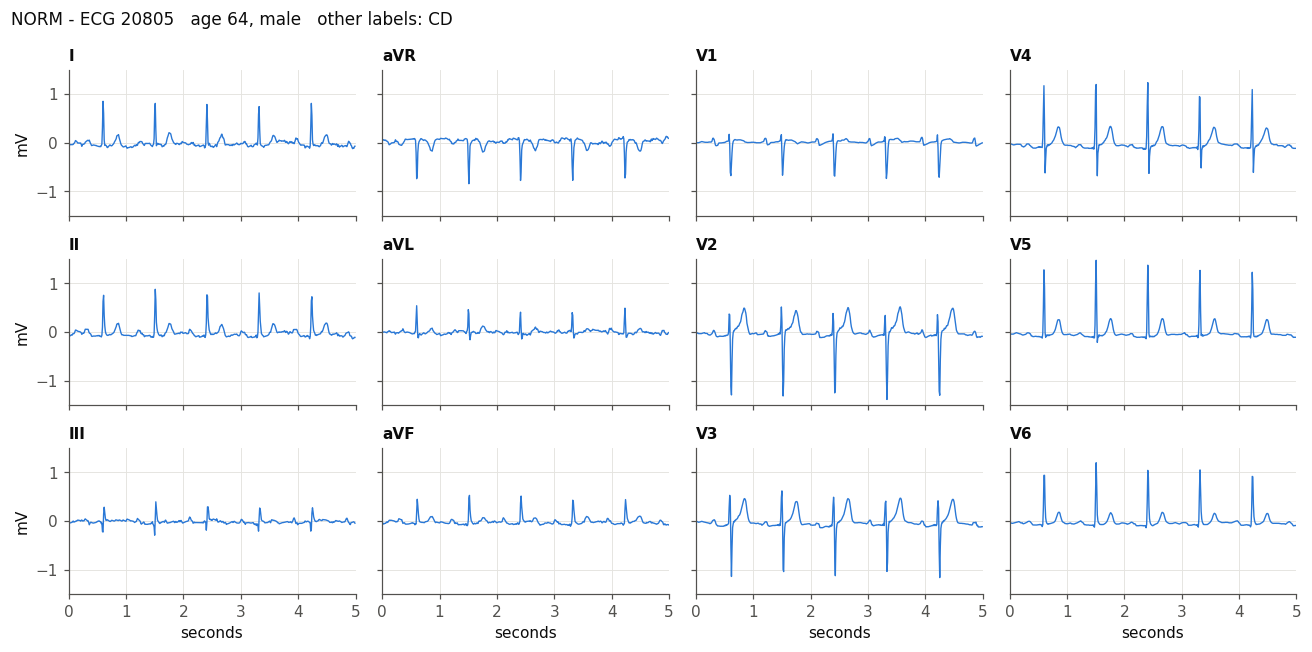

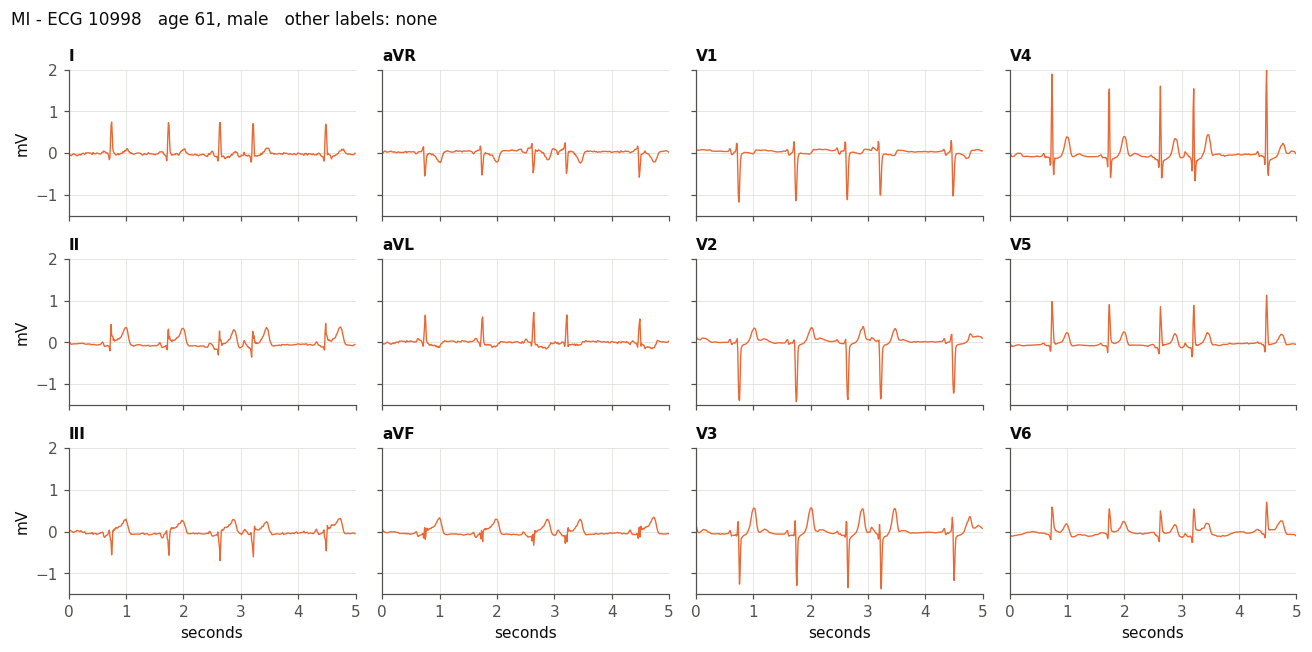

In [66]:
def plot_ecg(rec, group):
    sig = np.asarray(X[int(rec.row)], dtype=np.float32)          # (1000, 12)
    t = np.arange(sig.shape[0]) / FS
    keep = t < SECONDS
    ylim = (np.floor(sig.min() * 4) / 4, np.ceil(sig.max() * 4) / 4)
    fig, axes = plt.subplots(3, 4, figsize=(12, 6), sharex=True, sharey=True)
    for i, row_ in enumerate(LAYOUT):
        for j, lead in enumerate(row_):
            ax = axes[i, j]
            ax.plot(t[keep], sig[keep, LEADS.index(lead)], color=GROUP_COLOR[group], linewidth=0.9)
            ax.set_title(lead, fontsize=10)
            ax.set_ylim(*ylim)
            ax.set_xlim(0, SECONDS)
            ax.set_xticks(np.arange(0, SECONDS + 1, 1))
    for ax in axes[-1]:
        ax.set_xlabel("seconds")
    for ax in axes[:, 0]:
        ax.set_ylabel("mV")
    others = [c for c in CLASSES if rec[c] == 1 and c != group]
    age = "de-identified (>89)" if rec.age > 100 else f"{rec.age:.0f}"
    fig.suptitle(f"{group} - ECG {int(rec.ecg_id)}   age {age}, {'female' if rec.sex == 1 else 'male'}"
                 f"   other labels: {', '.join(others) or 'none'}", x=0.01, ha="left", fontsize=11)
    fig.tight_layout()
    return fig

reps = {g: representative(g) for g in ["NORM", "MI"]}
summary_reps = pd.DataFrame({
    g: dict(ecg_id=int(r.ecg_id), age=r.age_clean, sex="female" if r.sex == 1 else "male",
            target_age=r.age_target, age_band_used=r.band_used, candidates=r.n_candidates,
            group_median_age=trd.loc[trd.group == g, "age_clean"].median())
    for g, r in reps.items()}).T
display(summary_reps)
for g, rec in reps.items():
    fig = plot_ecg(rec, g)
    plt.show()

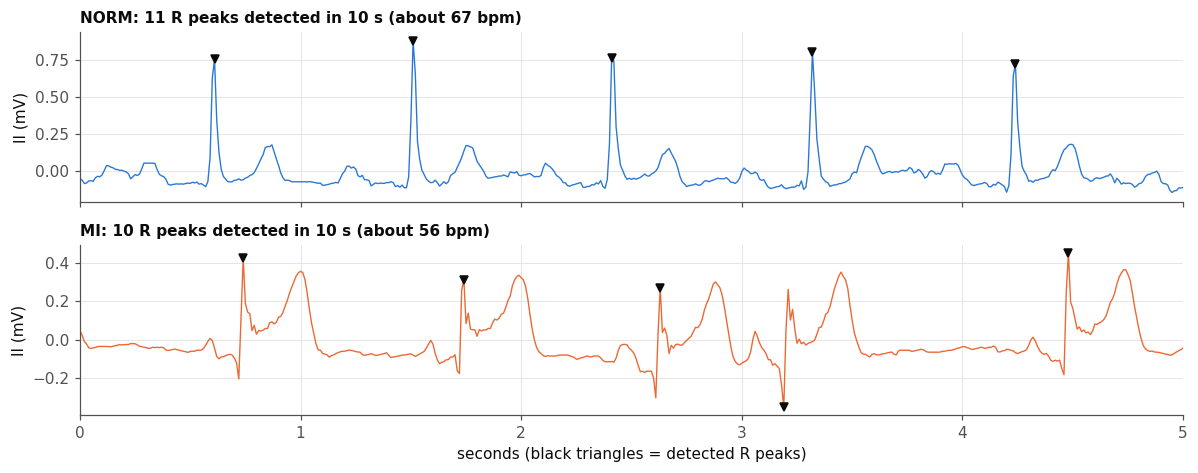

In [56]:
from scipy.signal import find_peaks, medfilt

PRE, POST = 0.25, 0.45                    # seconds before / after the R peak
pre, post = int(PRE * FS), int(POST * FS)
t_beat = np.arange(-pre, post) / FS
REF = LEADS.index("II")                   # lead used only to FIND the beats; all leads are cut at those positions

def detect_r(lead_sig):
    x = lead_sig - medfilt(lead_sig, 61)                                  # baseline removal
    slope = np.convolve(np.abs(np.diff(x, prepend=x[0])), np.ones(5) / 5, mode="same")
    peaks, _ = find_peaks(slope, height=0.5 * slope.max(), distance=int(0.3 * FS))
    snapped = np.unique([max(0, p - 5) + int(np.argmax(np.abs(x[max(0, p - 5):p + 6]))) for p in peaks])
    if len(snapped) >= 3:                      # drop noise/T-wave peaks much smaller than the typical QRS
        amp = np.abs(x[snapped])
        snapped = snapped[amp >= 0.5 * np.percentile(amp, 75)]
    return snapped, x

def median_beat(sig):
    r_all, _ = detect_r(sig[:, REF])
    hr = 60.0 / np.median(np.diff(r_all) / FS) if len(r_all) >= 2 else np.nan
    r = r_all[(r_all - pre >= 0) & (r_all + post <= sig.shape[0])]       # only complete windows
    if len(r) < 3:
        return None, hr
    beats = np.stack([sig[i - pre:i + post] for i in r])                  # (n_beats, window, 12)
    beats = beats - beats[:, :5].mean(axis=1, keepdims=True)
    return np.median(beats, axis=0), hr

# --- Detection check on the two representative recordings (lead II, first 5 s) ---
fig, axes = plt.subplots(2, 1, figsize=(11, 4.4), sharex=True)
for ax, (g, rec) in zip(axes, reps.items()):
    sig = np.asarray(X[int(rec.row)], dtype=np.float32)
    r, _ = detect_r(sig[:, REF])
    t = np.arange(len(sig)) / FS
    ax.plot(t, sig[:, REF], color=GROUP_COLOR[g], linewidth=0.9)
    ax.plot(r / FS, sig[r, REF], "v", color=INK, markersize=5)
    ax.set_xlim(0, 5); ax.set_ylabel("II (mV)")
    ax.set_title(f"{g}: {len(r)} R peaks detected in 10 s (about {60 / np.median(np.diff(r) / FS):.0f} bpm)", fontsize=10)
axes[-1].set_xlabel("seconds (black triangles = detected R peaks)")
fig.tight_layout()
#save_fig(fig, "04b_r_peak_detection_check.png")
plt.show()

NORM: 1496 recordings used, 4 skipped (fewer than 3 usable beats); median heart rate 68 bpm
MI: 1474 recordings used, 26 skipped (fewer than 3 usable beats); median heart rate 69 bpm


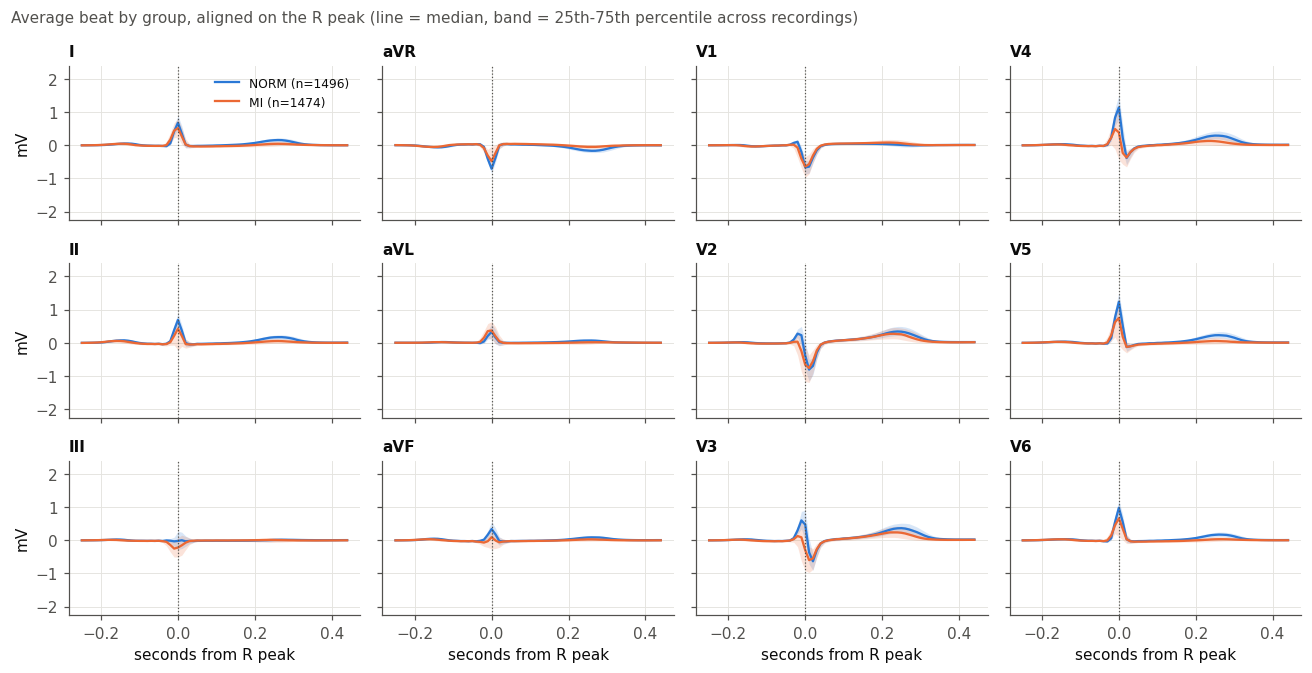

In [67]:
MAX_PER_GROUP = 1500          # recordings per group (random, training partition) 
AGE_RANGE = (40,70)              
rng = np.random.default_rng(784)

beats, hrs = {}, {}
for g in ["NORM", "MI"]:
    m = (bdf.group == g) & tr
    if AGE_RANGE:
        m &= bdf.age_clean.between(*AGE_RANGE)
    rows_g = bdf.loc[m, "row"].to_numpy()
    if len(rows_g) > MAX_PER_GROUP:
        rows_g = rng.choice(rows_g, MAX_PER_GROUP, replace=False)
    out, hr_list, skipped = [], [], 0
    for rw in rows_g:
        mb, hr = median_beat(np.asarray(X[int(rw)], dtype=np.float32))
        if mb is None:
            skipped += 1
            continue
        out.append(mb); hr_list.append(hr)
    beats[g], hrs[g] = np.stack(out), np.array(hr_list)
    print(f"{g}: {len(out)} recordings used, {skipped} skipped (fewer than 3 usable beats); "
          f"median heart rate {np.nanmedian(hrs[g]):.0f} bpm")

lo_hi = np.concatenate([np.percentile(beats[g], [5, 95], axis=0).ravel() for g in beats])
ylim = (lo_hi.min() * 1.1, lo_hi.max() * 1.1)
fig, axes = plt.subplots(3, 4, figsize=(12, 6.2), sharex=True, sharey=True)
for i, row_ in enumerate(LAYOUT):
    for j, lead in enumerate(row_):
        ax = axes[i, j]
        k = LEADS.index(lead)
        for g in ["NORM", "MI"]:
            q25, med, q75 = np.percentile(beats[g][:, :, k], [25, 50, 75], axis=0)
            ax.fill_between(t_beat, q25, q75, color=GROUP_COLOR[g], alpha=0.18, linewidth=0)
            ax.plot(t_beat, med, color=GROUP_COLOR[g], linewidth=1.5, label=f"{g} (n={len(beats[g])})")
        ax.axvline(0, color=MUTED, linestyle=":", linewidth=0.8)
        ax.set_title(lead, fontsize=10)
        ax.set_ylim(*ylim)
for ax in axes[-1]:
    ax.set_xlabel("seconds from R peak")
for ax in axes[:, 0]:
    ax.set_ylabel("mV")
axes[0, 0].legend(loc="upper right", fontsize=8)
fig.suptitle("Average beat by group, aligned on the R peak (line = median, band = 25th-75th percentile across recordings)",
             x=0.01, ha="left", fontsize=10, color=MUTED)
fig.tight_layout()
plt.show()

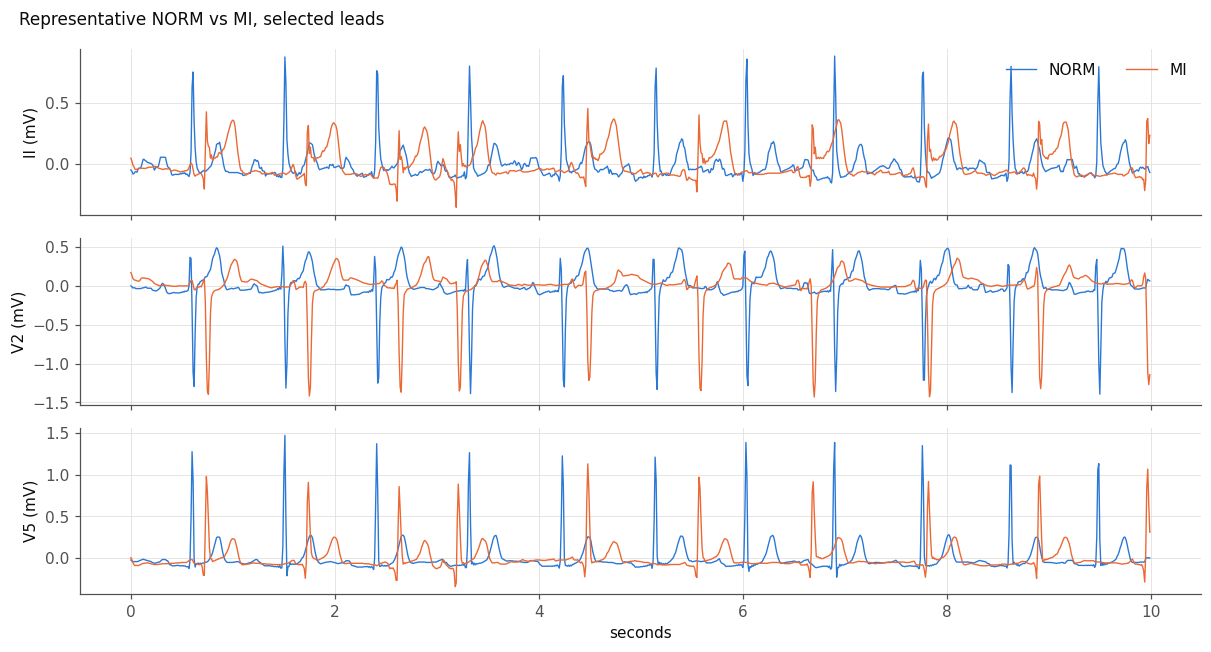

In [68]:
# Same two recordings, three informative leads overlaid (NORM blue, MI orange), full 10 s
reps = {g: representative(g) for g in ["NORM", "MI"]}
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, lead in zip(axes, ["II", "V2", "V5"]):
    for g, rec in reps.items():
        sig = np.asarray(X[int(rec.row)], dtype=np.float32)[:, LEADS.index(lead)]
        ax.plot(np.arange(len(sig)) / FS, sig, color=GROUP_COLOR[g], linewidth=0.9, label=g)
    ax.set_ylabel(f"{lead} (mV)")
axes[0].legend(loc="upper right", ncol=2)
axes[-1].set_xlabel("seconds")
fig.suptitle("Representative NORM vs MI, selected leads", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

## Check for class imbalance and summarise relevant dataset characteristics 
Two views: (a) the five-label multilabel problem used by the RF, CNN and multilabel logistic models
(diagnostic-eligible recordings only), and (b) the NORM-vs-MI binary problem.

In [69]:
elig = df[df.has_diagnostic_label == 1]
prev = pd.DataFrame({p: elig[elig.partition == p][CLASSES].mean() for p in PARTS})
prev["all"] = elig[CLASSES].mean()
prev_pct = (100 * prev).round(1)
display(prev_pct.rename_axis("label (% of eligible ECGs)"))

cardinality = elig[CLASSES].sum(axis=1).value_counts().sort_index().rename("recordings").to_frame()
cardinality["%"] = (100 * cardinality.recordings / len(elig)).round(1)
display(cardinality.rename_axis("labels per ECG"))

# Imbalance + naive baselines for the binary task
b = bdf.group.value_counts()
maj, mino = b.idxmax(), b.idxmin()
print(f"Binary cohort: {b.to_dict()}  majority:minority = {b.max() / b.min():.2f} : 1")
print(f"Majority-class accuracy (always predict {maj}): {b.max() / b.sum():.3f}")
print(f"AUPRC of a random classifier for MI = MI prevalence = {b['MI'] / b.sum():.3f}  (AUROC chance = 0.5)")
print("Smallest multilabel class:", prev["all"].idxmin(), f"({100 * prev['all'].min():.1f}% of eligible ECGs)")

,train,validation,test,all
label (% of eligible ECGs),,,,
NORM,44.5,44.5,44.6,44.5
MI,25.6,25.2,25.5,25.6
STTC,24.5,24.6,24.1,24.5
CD,22.9,23.1,23.0,22.9
HYP,12.4,12.5,12.1,12.4


,recordings,%
labels per ECG,,
1,16244,75.9
2,4068,19.0
3,919,4.3
4,157,0.7


Binary cohort: {'NORM': 9513, 'MI': 5468}  majority:minority = 1.74 : 1
Majority-class accuracy (always predict NORM): 0.635
AUPRC of a random classifier for MI = MI prevalence = 0.365  (AUROC chance = 0.5)
Smallest multilabel class: HYP (12.4% of eligible ECGs)


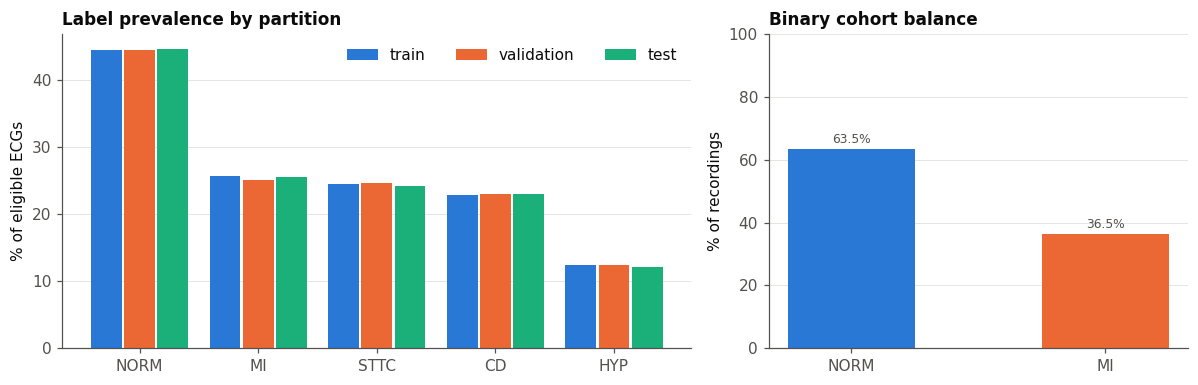

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [3, 2]})
w = 0.26
cols = {"train": BLUE, "validation": ORANGE, "test": AQUA}
for k, p in enumerate(PARTS):
    bars = axes[0].bar(np.arange(5) + (k - 1) * (w + 0.02), 100 * prev[p], width=w, color=cols[p], label=p)
axes[0].set_xticks(range(5), CLASSES)
axes[0].set_ylabel("% of eligible ECGs")
axes[0].set_title("Label prevalence by partition")
axes[0].legend(ncol=3, loc="upper right")
axes[0].grid(axis="x", visible=False)
bb = axes[1].bar(["NORM", "MI"], 100 * b.reindex(["NORM", "MI"]) / b.sum(), color=[BLUE, ORANGE], width=0.5)
axes[1].bar_label(bb, fmt="%.1f%%", padding=2, fontsize=8, color=MUTED)
axes[1].set(title="Binary cohort balance", ylim=(0, 100), ylabel="% of recordings")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

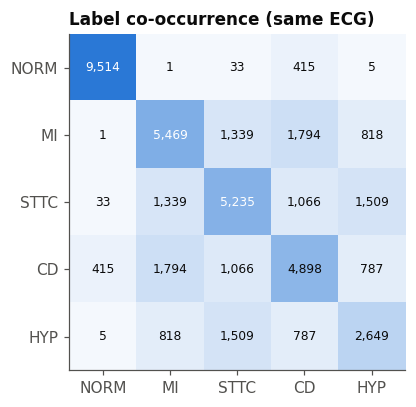

In [37]:
co = elig[CLASSES].T.dot(elig[CLASSES])
fig, ax = plt.subplots(figsize=(4.6, 3.8))
im = ax.imshow(co.to_numpy(), cmap=LinearSegmentedColormap.from_list("seq", ["#f4f8fd", BLUE]))
ax.set_xticks(range(5), CLASSES); ax.set_yticks(range(5), CLASSES); ax.grid(False)
for i in range(5):
    for j in range(5):
        v = co.to_numpy()[i, j]
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=8,
                color="white" if v > co.to_numpy().max() * 0.55 else INK)
ax.set_title("Label co-occurrence (same ECG)")
fig.tight_layout()
#save_fig(fig, "05_label_cooccurrence.png")
plt.show()

**How imbalance can affect results :**
- Accuracy is misleading: always predicting the majority group already scores the "majority-class accuracy" printed above.
  Report AUROC, AUPRC, and sensitivity/specificity or F1 per class instead.
- Models trained with a plain loss lean toward the majority class, so recall for the minority class (MI in the binary task;
  HYP in the multilabel task) drops at a 0.5 threshold. The logistic notebooks use 0.5, while the RF/CNN tune thresholds
  on validation, which is one reason their F1 values are not directly comparable (see section 6).
- Prevalence is nearly identical across train/validation/test, so the official split itself is not a source of imbalance shift.

## Combine the classification results from logistic regression, PCA + logistic regression, random forest, and CNN 

Sources for comparison include:
- **Random forest and CNN:** read from Thomas's saved result CSVs in the repo (held-out test set).
- **Logistic regression and PCA + logistic regressio e numbebed from the saved test-set outputs in `analysis/Shreya/logistic_regression_multilabel.ipynb` and
  `logistic_regression_binary.ipynell.

All multilabel rows use the same diagnostic-eligible test cohort (2,158 ECGs). The binary NORM-vs-MI task
(1,513 test ECGs) is a different problem and is reported separately.

In [42]:
## from Thomas CSVs
TH = "/work/users/m/b/mbonanno/BIOS784_Project/analysis/Thomas/"
rf_overall = pd.read_csv(TH + "Random_Forest/results/full/test_overall_performance.csv")
rf_class = pd.read_csv(TH + "Random_Forest/results/full/test_per_class_performance.csv")
cnn_overall = pd.read_csv(TH + "CNN/cnn_results/full/test_overall_performance.csv")
cnn_class = pd.read_csv(TH + "CNN/cnn_results/full/test_per_class_performance.csv")

## from Shreya's notebook outputs (threshold 0.5)
LR_OVERALL = [  # model, inputs, macro AUROC, macro AUPRC, macro F1 @0.5
    ("Logistic regression", "ECG only", 0.7617, 0.5516, 0.4144),
    ("Logistic regression", "ECG + age/sex", 0.7924, 0.5879, 0.4770),
    ("PCA + logistic regression", "ECG only", 0.7611, 0.5496, 0.4092),
]
LR_CLASS_AUROC = {  # test per-class AUROC (ECG only)
    "Logistic regression":       dict(NORM=0.7556, MI=0.7519, STTC=0.6925, CD=0.7948, HYP=0.8140),
    "PCA + logistic regression": dict(NORM=0.7553, MI=0.7515, STTC=0.6910, CD=0.7952, HYP=0.8126),
}
LR_CLASS_AUPRC = {
    "Logistic regression":       dict(NORM=0.6734, MI=0.5091, STTC=0.4493, CD=0.6206, HYP=0.5054),
    "PCA + logistic regression": dict(NORM=0.6717, MI=0.5064, STTC=0.4481, CD=0.6170, HYP=0.5047),
}
LR_BINARY = pd.DataFrame([  # NORM vs MI test set
    ("Logistic regression (60 features)", 0.8306, 0.7611, 0.7786, 0.6557, 0.5800, 0.8920),
    ("PCA + logistic regression (19 PCs)", 0.8136, 0.7346, 0.7581, 0.6250, 0.5545, 0.8744),
], columns=["model", "AUROC", "AUPRC", "accuracy", "F1", "sensitivity", "specificity"])

In [71]:
rows_ = [(m, i, a, p, f1, np.nan) for m, i, a, p, f1 in LR_OVERALL]
for name, tbl in [("Random forest", rf_overall), ("1D CNN", cnn_overall)]:
    for _, r in tbl.iterrows():
        inputs = "ECG only" if r.model.startswith("ECG only") else "ECG + age/sex"
        rows_.append((name, inputs, r.macro_AUROC, r.macro_AUPRC_AP, r.macro_F1_at_0_5, r.macro_F1))
comp = pd.DataFrame(rows_, columns=["model", "inputs", "macro_AUROC", "macro_AUPRC",
                                    "macro_F1_at_0.5", "macro_F1_tuned_threshold"])
order = ["Logistic regression", "PCA + logistic regression", "Random forest", "1D CNN"]
comp["model"] = pd.Categorical(comp.model, order, ordered=True)
comp = comp.sort_values(["model", "inputs"]).reset_index(drop=True)
comp["input_features"] = comp.model.astype(str).map({
    "Logistic regression": "60 summary stats", "PCA + logistic regression": "40 PCs of 60 stats",
    "Random forest": "60 summary stats", "1D CNN": "raw waveform"})
comp.loc[comp.inputs == "ECG + age/sex", "input_features"] += " + age, sex"
display(comp.round(3))
print("Best macro-AUROC:", comp.loc[comp.macro_AUROC.idxmax(), ["model", "inputs", "macro_AUROC"]].tolist())

,model,inputs,macro_AUROC,macro_AUPRC,macro_F1_at_0.5,macro_F1_tuned_threshold,input_features
0,Logistic regression,ECG + age/sex,0.792,0.588,0.477,NaN,"60 summary stats + age, sex"
1,Logistic regression,ECG only,0.762,0.552,0.414,NaN,60 summary stats
2,PCA + logistic regression,ECG only,0.761,0.550,0.409,NaN,40 PCs of 60 stats
3,Random forest,ECG + age/sex,0.823,0.646,0.552,0.602,"60 summary stats + age, sex"
4,Random forest,ECG only,0.809,0.634,0.495,0.597,60 summary stats
5,1D CNN,ECG + age/sex,0.924,0.812,0.694,0.741,"raw waveform + age, sex"
6,1D CNN,ECG only,0.922,0.809,0.714,0.737,raw waveform


Best macro-AUROC: ['1D CNN', 'ECG + age/sex', 0.9239059782317606]


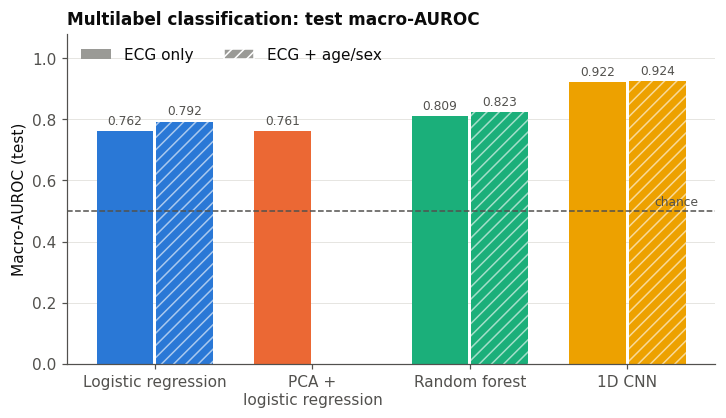

In [72]:
# Each model keeps one color in both charts below; dash marks the "+ age/sex" version.
MODEL_COLOR = dict(zip(order, [BLUE, ORANGE, AQUA, YELLOW]))
from matplotlib.patches import Patch

# Plot 1: macro-AUROC, ECG-only (solid) vs ECG + age/sex (dasb)
fams = order
fig, ax = plt.subplots(figsize=(7.6, 3.9))
w = 0.36
for k, inp in enumerate(["ECG only", "ECG + age/sex"]):
    for i, f in enumerate(fams):
        sel = comp[(comp.model == f) & (comp.inputs == inp)]
        if sel.empty:
            continue
        v = float(sel.macro_AUROC.iloc[0])
        x = i + (k - 0.5) * (w + 0.02)
        ax.bar(x, v, width=w, color=MODEL_COLOR[f], edgecolor="white" if k == 0 else "#ffffff99",
               hatch="///" if k else None, linewidth=0)
        ax.text(x, v + 0.012, f"{v:.3f}", ha="center", va="bottom", fontsize=8, color=MUTED)
ax.axhline(0.5, color=MUTED, linestyle="--", linewidth=1)
ax.text(len(fams) - 0.55, 0.51, "chance", ha="right", va="bottom", fontsize=8, color=MUTED)
ax.set_xticks(range(len(fams)), [f.replace(" + ", " +\n") for f in fams])
ax.set_ylim(0, 1.08); ax.set_ylabel("Macro-AUROC (test)")
ax.set_title("Multilabel classification: test macro-AUROC")
ax.legend(handles=[Patch(facecolor="#9a9a96", label="ECG only"),
                   Patch(facecolor="#9a9a96", hatch="///", edgecolor="white", label="ECG + age/sex")],
          loc="upper left", ncol=2)
ax.grid(axis="x", visible=False)
plt.show()

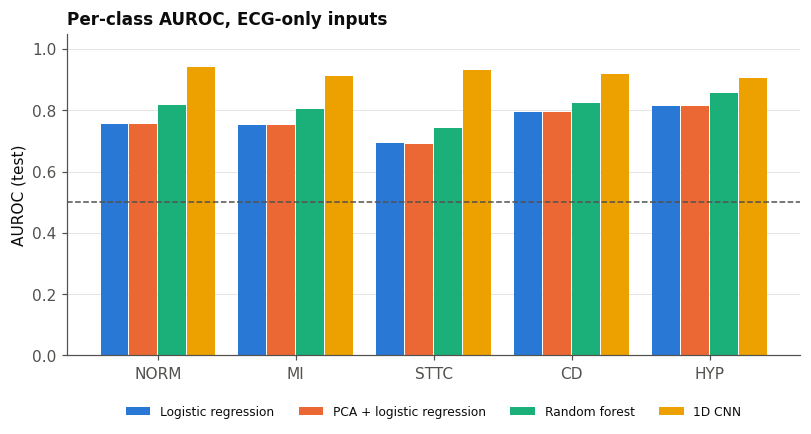

,Logistic regression,PCA + logistic regression,Random forest,1D CNN
per-class test AUROC (table view of chart),,,,
NORM,0.756,0.755,0.816,0.941
MI,0.752,0.752,0.805,0.913
STTC,0.692,0.691,0.742,0.932
CD,0.795,0.795,0.825,0.917
HYP,0.814,0.813,0.858,0.906


In [73]:
# Plot 2: per-class AUROC, ECG-only versions of every model
percls = {k: pd.Series(v) for k, v in LR_CLASS_AUROC.items()}
percls["Random forest"] = rf_class[rf_class.model == "ECG only"].set_index("class_name").AUROC
percls["1D CNN"] = cnn_class[cnn_class.model == "ECG only"].set_index("class_name").AUROC
pc = pd.DataFrame(percls).loc[CLASSES][order]
fig, ax = plt.subplots(figsize=(8.6, 3.8))
w = 0.2
for k, m in enumerate(order):
    col = MODEL_COLOR[m]
    xs = np.arange(5) + (k - 1.5) * (w + 0.01)
    ax.bar(xs, pc[m], width=w, color=col, label=m)
ax.axhline(0.5, color=MUTED, linestyle="--", linewidth=1)
ax.set_xticks(range(5), CLASSES); ax.set_ylim(0, 1.05)
ax.set_ylabel("AUROC (test)"); ax.set_title("Per-class AUROC, ECG-only inputs")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
ax.grid(axis="x", visible=False)
plt.show()
display(pc.round(3).rename_axis("per-class test AUROC (table view of chart)"))

In [74]:
# Binary NORM-vs-MI task (logistic models only: RF and CNN were not evaluated on this cohort)
display(LR_BINARY.round(3))

# Closest cross-model link to the binary task: MI one-vs-rest AUROC / AUPRC in the multilabel setting
mi_auc = pc.loc["MI"].rename("MI AUROC")
mi_ap = pd.Series({
    "Logistic regression": LR_CLASS_AUPRC["Logistic regression"]["MI"],
    "PCA + logistic regression": LR_CLASS_AUPRC["PCA + logistic regression"]["MI"],
    "Random forest": rf_class[(rf_class.model == "ECG only") & (rf_class.class_name == "MI")].average_precision.squeeze(),
    "1D CNN": cnn_class[(cnn_class.model == "ECG only") & (cnn_class.class_name == "MI")].average_precision.squeeze(),
}, name="MI AUPRC")
mi_tbl = pd.concat([mi_auc, mi_ap.reindex(mi_auc.index)], axis=1).round(3)
display(mi_tbl.rename_axis("MI one-vs-rest (multilabel cohort, ECG only)"))

,model,AUROC,AUPRC,accuracy,F1,sensitivity,specificity
0,Logistic regression (60 features),0.831,0.761,0.779,0.656,0.580,0.892
1,PCA + logistic regression (19 PCs),0.814,0.735,0.758,0.625,0.554,0.874


,MI AUROC,MI AUPRC
"MI one-vs-rest (multilabel cohort, ECG only)",,
Logistic regression,0.752,0.509
PCA + logistic regression,0.752,0.506
Random forest,0.805,0.610
1D CNN,0.913,0.802
